## Imports and Tokens

In [644]:
from matplotlib import pyplot as plt
import pandas as pd
import json
import random
from src.utils.entsoe_client import fetch_and_save_spot_prices

# Define the API tokens
# Personal renewables.ninja API token
with open(r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\secrets.json") as f:
    secrets = json.load(f)

ninja_token = secrets.get("ninja_token")
entsoe_api_key = secrets.get("entsoe_api_key")


## Data Loading and Cleaning

#### Spot data - ENTSOE API

In [645]:
# Spot market data 2019
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2019-01-01'
end_date = '2019-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Spot market data 2020
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2020-01-01'
end_date = '2020-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Load the data as a pandas DataFrame
spot_prices_2019 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2019.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2019['Price ct/KWH'] = spot_prices_2019['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

print(spot_prices_2019.head())
print("Average price 2019: ", spot_prices_2019['Price ct/KWH'].mean())

#2020
spot_prices_2020 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2020.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2020['Price ct/KWH'] = spot_prices_2020['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

#print("Average price 2020: ", spot_prices_2020['Price ct/KWH'].mean())

spot_prices_2020

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_24348\1402570545.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2019 = data = pd.read_csv(


           Date (CET)  Price (€/MWh)  Price ct/KWH
0 2019-01-01 00:00:00          28.32         2.832
1 2019-01-01 01:00:00          10.07         1.007
2 2019-01-01 02:00:00          -4.08        -0.408
3 2019-01-01 03:00:00          -9.91        -0.991
4 2019-01-01 04:00:00          -7.41        -0.741
Average price 2019:  3.7680148809523812


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_24348\1402570545.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2020 = data = pd.read_csv(


,Date (CET),Price (€/MWh),Price ct/KWH
0,2020-01-01 00:00:00,41.88,4.188
1,2020-01-01 01:00:00,38.60,3.860
2,2020-01-01 02:00:00,36.55,3.655
3,2020-01-01 03:00:00,32.32,3.232
4,2020-01-01 04:00:00,30.85,3.085
...,...,...,...
8755,2020-12-30 19:00:00,53.60,5.360
8756,2020-12-30 20:00:00,52.38,5.238
8757,2020-12-30 21:00:00,46.88,4.688
8758,2020-12-30 22:00:00,43.22,4.322


#### Electricity Prices over the years:  
Source: https://www.bdew.de/service/daten-und-grafiken/bdew-strompreisanalyse/
![image.png](attachment:image.png)

    Year  Beschaffung_Vetrieb  Netzentgelt  Mehrwertsteuer  Summe  Sonstige
0   2024                17.94        11.53            6.60  41.35      5.28
1   2023                23.83         9.52            7.30  45.73      5.08
2   2022                16.97         8.08            6.05  37.91      6.81
3   2021                 7.93         7.80            5.13  32.16     11.30
4   2020                 7.51         7.75            5.08  31.81     11.47
5   2019                 7.09         7.39            4.86  30.46     11.12
6   2018                 7.09         7.29            4.71  29.47     10.38
7   2017                 7.05         7.51            4.67  29.28     10.05
8   2016                 7.05         7.51            4.60  28.80      9.64
9   2015                 7.38         6.63            4.58  28.70     10.11
10  2014                 7.38         6.63            4.56  29.14     10.57


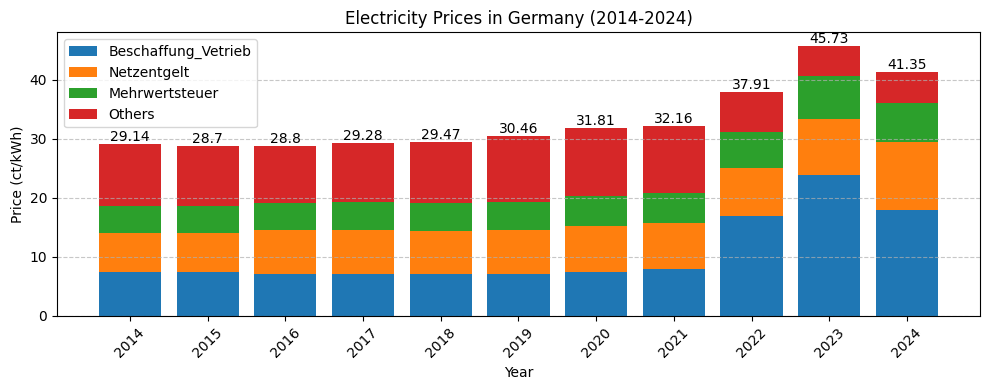

In [646]:
electricity_prices = {
    "Year": [2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014],
    "Beschaffung_Vetrieb": [17.94, 23.83, 16.97, 7.93, 7.51, 7.09, 7.09, 7.05, 7.05, 7.38, 7.38],
    "Netzentgelt": [11.53, 9.52, 8.08, 7.80, 7.75, 7.39, 7.29, 7.51, 7.51, 6.63, 6.63],
    "Mehrwertsteuer": [6.60, 7.30, 6.05, 5.13, 5.08, 4.86, 4.71, 4.67, 4.60, 4.58, 4.56],
    "Summe": [41.35, 45.73, 37.91, 32.16, 31.81, 30.46, 29.47, 29.28, 28.80, 28.70, 29.14]
} #' IN kwH'

# Create DataFrame and add Sonstige column (EEG-Umlage, KWK-Aufschlag, Stromsteuer,...))
electricity_prices_df = pd.DataFrame(electricity_prices)
electricity_prices_df['Sonstige'] = electricity_prices_df['Summe'] - (electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'])
print(electricity_prices_df)

# Plot the data as a stacked bar chart
plt.figure(figsize=(10,4))
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Beschaffung_Vetrieb'], label='Beschaffung_Vetrieb')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Netzentgelt'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'], label='Netzentgelt')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Mehrwertsteuer'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'], label='Mehrwertsteuer')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Sonstige'],bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'], label='Others')
plt.xlabel('Year')
plt.ylabel('Price (ct/kWh)')
for i in range(len(electricity_prices_df)):
    plt.text(electricity_prices_df['Year'][i], electricity_prices_df['Summe'][i] + 0.5, str(electricity_prices_df['Summe'][i]), ha='center') #add values
plt.title('Electricity Prices in Germany (2014-2024)')
plt.xticks(electricity_prices_df['Year'], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Load Household data

- filtered_df = Data of all households in 2019
- filtered_df_test = Data of all households in 2020

In [647]:
#Load pickle into dataframe
hh_path = r"local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
start_date = '2019-01-01'
end_date = '2019-12-31'
start_date_test = '2020-01-01'
end_date_test = '2020-12-31'
keyword = 'SFH' # Single Family Households

data_allhouseholds = pd.read_pickle(hh_path)
mask_model = (data_allhouseholds.index >= start_date) & (data_allhouseholds.index < end_date)
mask_test = (data_allhouseholds.index >= start_date_test) & (data_allhouseholds.index < end_date_test)


##### 2019

In [648]:
data_allhouseholds_model = data_allhouseholds.loc[mask_model]

# Extract columns that contain the keyword in their name
filtered_df = data_allhouseholds_model.filter(like=keyword)
filtered_df = filtered_df.drop(columns=['SFH34_P_TOT']) # TODO: SHOW WHY Household 34 is shit

# turn unit to kWh
filtered_df = filtered_df/1000

print("Number of households: ", len(filtered_df.columns))
filtered_df.head()


Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00+00:00,0.161493,0.378307,0.555783,0.472945,0.276283,0.141515,1.263900,0.138280,0.167612,0.204542,...,0.187705,0.278985,0.095981,0.091195,0.130055,0.183680,0.172490,0.341785,0.552966,0.137806
2019-01-01 01:00:00+00:00,0.201888,0.379044,0.446765,0.303302,0.254865,0.137292,1.251248,0.109699,0.171209,0.207164,...,0.198733,0.309711,0.097085,0.177395,0.111404,0.080881,0.115421,0.335813,0.326356,0.146449
2019-01-01 02:00:00+00:00,0.156627,0.381565,0.301362,0.142379,0.198773,0.133582,1.121481,0.072142,0.159650,0.214528,...,0.192340,0.399156,0.102519,0.236366,0.118093,0.119899,0.145594,0.211437,0.263901,0.156046
2019-01-01 03:00:00+00:00,0.155399,0.427539,0.307746,0.152653,0.241786,0.147410,0.990431,0.102894,0.124849,0.194947,...,0.224510,0.149937,0.096335,0.186000,0.116369,0.077734,0.112445,0.146979,0.303394,0.176267
2019-01-01 04:00:00+00:00,0.112611,0.309020,0.326347,0.208406,0.165343,0.126375,0.314959,0.091286,0.175570,0.283466,...,0.182807,0.186482,0.095063,0.171690,0.122021,0.076919,0.078177,0.141085,0.290612,0.286422


##### 2020

In [649]:
data_allhouseholds_test = data_allhouseholds.loc[mask_test]

# Extract columns that contain the keyword in their name
filtered_df_test = data_allhouseholds_test.filter(like=keyword)
filtered_df_test = filtered_df_test.drop(columns=['SFH34_P_TOT'])

# turn unit to kWh
filtered_df_test = filtered_df_test/1000

print("Number of households: ", len(filtered_df_test.columns))

filtered_df_test

Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.163916,0.373391,0.426055,0.175637,0.880133,0.147927,1.028024,0.240754,0.093248,0.596717,...,0.276218,0.344925,0.088926,0.599022,0.111477,0.150296,0.199717,0.149463,0.404039,0.151883
2020-01-01 01:00:00+00:00,0.096884,0.433742,0.414172,0.132504,0.568079,0.142868,0.659489,0.181140,0.120597,1.297585,...,0.233408,0.200887,0.095167,0.585296,0.096038,0.081426,0.206756,0.157918,0.434017,0.151909
2020-01-01 02:00:00+00:00,0.207420,0.455052,0.373124,0.198556,0.641215,0.136044,0.358423,0.109398,0.137314,1.125870,...,0.193405,0.175490,0.103124,0.578868,0.098231,0.083770,0.138144,0.159315,0.546359,0.171845
2020-01-01 03:00:00+00:00,0.109694,0.377600,0.365616,0.150788,0.538791,0.135456,0.349706,0.102048,0.093597,0.299468,...,0.214475,0.146496,0.093065,0.255038,0.100640,0.060413,0.129610,0.138526,0.334807,0.128404
2020-01-01 04:00:00+00:00,0.193015,0.277767,0.374640,0.100247,0.368989,0.145098,0.348721,0.110583,0.123097,0.319027,...,0.205340,0.220397,0.076818,0.161516,0.108735,0.090928,0.077703,0.139926,0.224035,0.150912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.285882,1.288372,0.487239,0.444430,0.621300,0.287039,1.417525,0.368618,0.992046,0.363517,...,0.299486,1.921150,0.119291,0.597287,0.373720,0.445905,0.541438,0.217190,1.002722,0.271178
2020-12-30 20:00:00+00:00,0.177044,0.443794,0.510834,0.503695,0.597298,0.328044,0.874725,0.298788,0.866079,0.226329,...,0.297135,0.430116,0.114994,0.569243,0.184183,0.223751,0.422432,0.210398,0.553453,0.291510
2020-12-30 21:00:00+00:00,0.240316,0.433245,0.352619,0.454367,0.504256,0.287266,1.038879,0.294333,0.427432,0.178664,...,0.209374,0.404800,0.079628,0.580204,0.197486,0.110087,0.342846,0.187408,0.559419,0.214913


# Models

## 1. Model: Standardlastprofil: 
- Load data: Datensatz: SLP 2019 der Stadtwerke Groß-Gerau Versorgung GmbH: https://ggv-energie.de/cms/netz/allgemeine-daten/netzbilanzierung-download-aller-profile.php
  - Datensatz enthält Standardlastprofil eines typischen Einfamilien Haushalt (H00)
- Vorhersage für 2020, auf Basis des Standardlastprofils
  - Standard Werktag auf Basis vom 
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten



### Load SLP data and normalize to 3000kwh

Load Data

In [650]:
file_path = r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\data\slp\GGV_SLP_1000_MWh_2019_01.xlsx"
sheet_name = "15Min - SLP 2019" # Single Load Profile 2019

data_15min_slp_2019 = pd.read_excel(file_path, sheet_name=sheet_name)
data_15min_slp_2019.head() 

,Messwert-Nr.,Wochentag,Datum,Zeitstempel von,Zeitstempel bis,MP von,MP bis,H00 [kW],H00 [kWh]
0,1,2,2019-01-01,2019-01-01 00:00:00,2019-01-01 00:15:00,00:00,00:15,145.200,36.300
1,2,2,2019-01-01,2019-01-01 00:15:00,2019-01-01 00:30:00,00:15,00:30,140.112,35.028
2,3,2,2019-01-01,2019-01-01 00:30:00,2019-01-01 00:45:00,00:30,00:45,135.720,33.930
3,4,2,2019-01-01,2019-01-01 00:45:00,2019-01-01 01:00:00,00:45,01:00,130.732,32.683
4,5,2,2019-01-01,2019-01-01 01:00:00,2019-01-01 01:15:00,01:00,01:15,127.236,31.809


Data Prepapration

In [651]:
data_15min_slp_2019.drop(columns=['Messwert-Nr.','MP von', 'MP bis'], inplace=True)

In [652]:
#Fasse Zeitstempel pro Stunde zusammen und summiere H00 [kW] in neuer df
data_15min_slp_2019['Time'] = data_15min_slp_2019['Zeitstempel von'].dt.floor('h')

data_slp_hourly_2019 = data_15min_slp_2019.groupby('Time').agg({'H00 [kW]': 'sum'}).reset_index()
data_slp_hourly_2019['H00 [kWh]'] = data_slp_hourly_2019['H00 [kW]'] / 4 
#add 'Wochentag'
data_slp_hourly_2019['Weekday'] = data_slp_hourly_2019['Time'].dt.day_name()

#add Arbeitstag oder Wochenende als neue Spalte
data_slp_hourly_2019['Weekend'] = data_slp_hourly_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

#add Hour and save as int
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Time'].dt.time
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Hour'].apply(lambda x: x.hour)

#Normalizing the values to a "average household" with 3000 kWh  
data_slp_hourly_2019['H00_Norm [kWh]'] = data_slp_hourly_2019['H00 [kWh]'] /data_slp_hourly_2019['H00 [kWh]'].sum()*3000

data_slp_hourly_2019

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656
...,...,...,...,...,...,...,...
8754,2019-12-31 19:00:00,656.444,164.111,Tuesday,0,19,0.492333
8755,2019-12-31 20:00:00,574.216,143.554,Tuesday,0,20,0.430662
8756,2019-12-31 21:00:00,557.048,139.262,Tuesday,0,21,0.417786
8757,2019-12-31 22:00:00,640.876,160.219,Tuesday,0,22,0.480657


### Prediction for 2020
auf Basis des Standardlastprofils
  - Standard Werktag berechnen 
  - Standard Wochenende
  - Diese WErte auf Prediciton profil von 2020 übertragen.
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)


In [653]:
#Calculate an average Weekday (Monday - Fridaay means Weekend == 0)
weekday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 0]

average_weekday = weekday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekday.head()

,Hour,H00_Norm [kWh]
0,0,0.263477
1,1,0.231250
2,2,0.221361
3,3,0.219777
4,4,0.227036


Calculate an average Weekday (Monday - Fridaay means Weekend == 0)

In [654]:
#Calculate an average Weekday (Saturday/Sunday means Weekend == 1

weekendday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 1]
average_weekendday = weekendday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekendday.head()

,Hour,H00_Norm [kWh]
0,0,0.279139
1,1,0.241221
2,2,0.226147
3,3,0.219243
4,4,0.217916


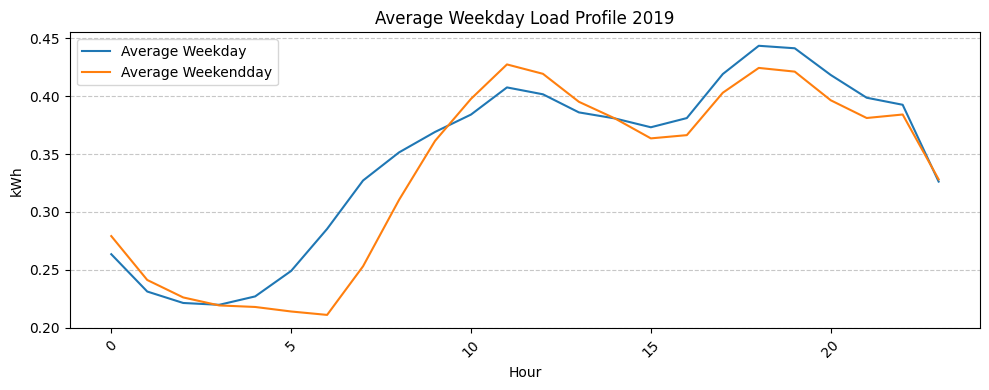

In [655]:
#Plots
#Plot
plt.figure(figsize=(10,4))
plt.plot(average_weekday['Hour'], average_weekday['H00_Norm [kWh]'], label='Average Weekday')
plt.plot(average_weekendday['Hour'], average_weekendday['H00_Norm [kWh]'], label='Average Weekendday')
plt.xlabel('Hour')
plt.ylabel('kWh')
plt.title('Average Weekday Load Profile 2019')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


#### Prediciton profil von 2020 erstellen
- range aufstellen
- if Weekday -> average_weekday matchen zu Kalender auf Basis von Stunden
- if Weekend -> average_weekendday matchen zu Kalender auf Basis von Stunden

In [656]:
# Define the target full-year date range
start_date_2020 = '2020-01-01'
end_date_2020 = '2020-12-31'
date_range = pd.date_range(start=start_date_2020, end=end_date_2020, freq='h', tz='UTC') # hourly data

# Create a DataFrame with the full-year date range
model1_prediciton_2020 = pd.DataFrame(index=date_range)

# add Day informations
model1_prediciton_2020['Hour'] = model1_prediciton_2020.index.hour
model1_prediciton_2020['Weekday'] = model1_prediciton_2020.index.day_name()
model1_prediciton_2020['Weekend'] = model1_prediciton_2020['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

model1_prediciton_2020['H00_predicted [kWh]']=0
model1_prediciton_2020 = model1_prediciton_2020[:-1] #delete last row (0Uhr)

model1_prediciton_2020.head()

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0
2020-01-01 01:00:00+00:00,1,Wednesday,0,0
2020-01-01 02:00:00+00:00,2,Wednesday,0,0
2020-01-01 03:00:00+00:00,3,Wednesday,0,0
2020-01-01 04:00:00+00:00,4,Wednesday,0,0


In [657]:
# add information for model1_prediciton_2020['H00_predicted [kWh]']. If Weekday == 0 then take average_weekday else average_weekendday and match with Hour
for index, row in model1_prediciton_2020.iterrows():
    if row['Weekend'] == 0:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]
    else:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekendday[average_weekendday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_24348\2267906313.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.2634770519382463' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


In [658]:
model1_prediciton_2020

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0.263477
2020-01-01 01:00:00+00:00,1,Wednesday,0,0.231250
2020-01-01 02:00:00+00:00,2,Wednesday,0,0.221361
2020-01-01 03:00:00+00:00,3,Wednesday,0,0.219777
2020-01-01 04:00:00+00:00,4,Wednesday,0,0.227036
...,...,...,...,...
2020-12-30 19:00:00+00:00,19,Wednesday,0,0.441350
2020-12-30 20:00:00+00:00,20,Wednesday,0,0.418301
2020-12-30 21:00:00+00:00,21,Wednesday,0,0.398629
2020-12-30 22:00:00+00:00,22,Wednesday,0,0.392547


### Test the model	
- Vergleich mit realem Datensatz von allen Haushalten. Berechne MAPE
- Preisberechnugn für 2020

In [659]:
# Define actual_load_profile2020
actual_load_profile2020 = filtered_df_test

# Display the actual load profile for 2020
actual_load_profile2020.head()

#Normalize to 3000 kWh
for column in actual_load_profile2020.columns:
    actual_load_profile2020[column] = actual_load_profile2020[column] / actual_load_profile2020[column].sum() * 3000

# Display the actual load profile for 2020
actual_load_profile2020.head()

,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.235083,0.338549,0.421355,0.165795,0.536347,0.130392,1.260980,0.312827,0.100835,0.529366,...,0.316237,0.288901,0.238178,0.565123,0.230555,0.195297,0.216712,0.168074,0.314421,0.188607
2020-01-01 01:00:00+00:00,0.138948,0.393269,0.409602,0.125080,0.346184,0.125933,0.808933,0.235367,0.130411,1.151129,...,0.267225,0.168259,0.254894,0.552174,0.198624,0.105806,0.224350,0.177582,0.337750,0.188640
2020-01-01 02:00:00+00:00,0.297474,0.412591,0.369007,0.187430,0.390752,0.119917,0.439644,0.142148,0.148487,0.998795,...,0.221426,0.146986,0.276205,0.546109,0.203159,0.108852,0.149899,0.179153,0.425174,0.213396
2020-01-01 03:00:00+00:00,0.157319,0.342366,0.361583,0.142339,0.328336,0.119399,0.428951,0.132597,0.101213,0.265667,...,0.245548,0.122702,0.249265,0.240605,0.208143,0.078502,0.140639,0.155775,0.260545,0.159452
2020-01-01 04:00:00+00:00,0.276814,0.251848,0.370506,0.094630,0.224859,0.127898,0.427743,0.143687,0.133114,0.283019,...,0.235090,0.184600,0.205749,0.152376,0.224884,0.118153,0.084315,0.157349,0.174343,0.187402


In [660]:
# NMAE
def calculate_nmae(actual_df, predicted_df):
    """
    Calculate the Normalized Mean Absolute Error (NMAE) between actual and predicted values.

    Parameters:
    - actual_df (pd.DataFrame or pd.Series): The DataFrame or Series containing actual values.
    - predicted_df (pd.DataFrame or pd.Series): The DataFrame or Series containing predicted values.

    Returns:
    - float: The NMAE value as a percentage.
    """
    if not actual_df.index.equals(predicted_df.index):
        raise ValueError("The indices of actual_df and predicted_df must match.")
    absolute_errors = abs(actual_df - predicted_df)
    mae = absolute_errors.mean() # Compute the Mean Absolute Error (MAE)
    nmae = mae / actual_df.mean() # Compute the Normalized Mean Absolute Error (NMAE)
    return 100 * nmae

nmae_sum = 0
for column in actual_load_profile2020.columns:
    nmae = calculate_nmae(actual_load_profile2020[column], model1_prediciton_2020['H00_predicted [kWh]'])
    print(f"NMAE for {column}: {nmae:.2f} %")
    nmae_sum = nmae_sum + nmae

print(f"Average NMAE: {nmae_sum/len(actual_load_profile2020.columns):.2f} %")


NMAE for SFH3_P_TOT: 58.07 %
NMAE for SFH4_P_TOT: 39.39 %
NMAE for SFH5_P_TOT: 50.62 %
NMAE for SFH7_P_TOT: 50.45 %
NMAE for SFH9_P_TOT: 62.75 %
NMAE for SFH12_P_TOT: 67.07 %
NMAE for SFH14_P_TOT: 60.65 %
NMAE for SFH16_P_TOT: 69.87 %
NMAE for SFH18_P_TOT: 71.88 %
NMAE for SFH19_P_TOT: 43.41 %
NMAE for SFH20_P_TOT: 49.42 %
NMAE for SFH21_P_TOT: 37.17 %
NMAE for SFH22_P_TOT: 48.06 %
NMAE for SFH27_P_TOT: 34.20 %
NMAE for SFH28_P_TOT: 57.14 %
NMAE for SFH29_P_TOT: 52.29 %
NMAE for SFH30_P_TOT: 61.87 %
NMAE for SFH32_P_TOT: 48.67 %
NMAE for SFH36_P_TOT: 54.38 %
NMAE for SFH38_P_TOT: 33.25 %
NMAE for SFH39_P_TOT: 35.44 %
Average NMAE: 51.72 %


#### Cost Comparison
- price calculation 2020 (dynamic, static prices)
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices)
- Auswertung

In [661]:
spot_prices_2020
#use 'Date (CET' as index
spot_prices_2020.set_index('Date (CET)', inplace=True)
spot_prices_2020


,Price (€/MWh),Price ct/KWH
Date (CET),,
2020-01-01 00:00:00,41.88,4.188
2020-01-01 01:00:00,38.60,3.860
2020-01-01 02:00:00,36.55,3.655
2020-01-01 03:00:00,32.32,3.232
2020-01-01 04:00:00,30.85,3.085
...,...,...
2020-12-30 19:00:00,53.60,5.360
2020-12-30 20:00:00,52.38,5.238
2020-12-30 21:00:00,46.88,4.688


In [662]:
# Preisberechnung

# Define the missing variables # TODO: Replace with actual values
consumption_dependent_fixed_costs = 19.71  # ct per KwH 2024 value Tibber - Example value, replace with actual value
Consumption_independent_base_price = 15.73  # €/Monat - 2024 value Tibber - Example value, replace with actual value

# Calculate dynamic price in 2020 und rechne Cent in euro
dynamic_price_per_kwh_2020 = (spot_prices_2020['Price ct/KWH'] + consumption_dependent_fixed_costs)/100
dynamic_price_permonth = Consumption_independent_base_price # ist schon in Euro!

# Calculate fixed price in 2020
fixed_price_per_kwh = electricity_prices_df.loc[electricity_prices_df['Year'] == 2020, 'Summe'].values[0]/100 # /100, damit in Euro
print("Fixed price per kWh in 2020 [Euro] : ", fixed_price_per_kwh)

Fixed price per kWh in 2020 [Euro] :  0.3181


##### Actual Costs

In [663]:
# Calculate the annual costs for each household based on dynamic price

def calculate_annual_dynamic_costs(df_load_profile, df_dynamic_price):
    # Ensure both indices are timezone-aware
    if df_load_profile.index.tz is None:
        df_load_profile.index = df_load_profile.index.tz_localize('UTC')
    if df_dynamic_price.index.tz is None:
        df_dynamic_price.index = df_dynamic_price.index.tz_localize('UTC')
    
    # Calculate the total costs of the household
    annual_costs = ((df_load_profile * df_dynamic_price).sum(axis=0))
    return annual_costs

# Calculate the annual costs for each household based on static price
def calculate_annual_static_costs(df_load_profile, static_price_per_kwh):
    
    annual_costs = (df_load_profile.sum(axis=0) * static_price_per_kwh)

    return annual_costs

In [664]:
# Calculate the annual costs for each household and compare fixed and dynamic prices

print("------Result------")

sum_difference = 0
list_of_households_fixed_cheaper = []
list_of_households_dynamic_cheaper = []

for column in actual_load_profile2020.columns:
    print(f"Household: ", column)
    annual_costs_dynamic = calculate_annual_dynamic_costs(actual_load_profile2020[column], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
    print(f"Annual actual costs for {column} based on dynamic prices: {annual_costs_dynamic:.2f} €")
    annual_costs_static = calculate_annual_static_costs(actual_load_profile2020[column], fixed_price_per_kwh)#in €
    print(f"Annual actual costs for {column} based on fixed prices: {annual_costs_static:.2f} €")

    
    if annual_costs_dynamic < annual_costs_static:
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_costs_static - annual_costs_dynamic, "Euro")
        list_of_households_dynamic_cheaper.append(column)
    else:
        print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_costs_dynamic - annual_costs_static, "Euro")
        list_of_households_fixed_cheaper.append(column)
   

print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)


------Result------
Household:  SFH3_P_TOT
Annual actual costs for SFH3_P_TOT based on dynamic prices: 867.47 €
Annual actual costs for SFH3_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  86.83484099337579 Euro
Household:  SFH4_P_TOT
Annual actual costs for SFH4_P_TOT based on dynamic prices: 874.87 €
Annual actual costs for SFH4_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.43267412409489 Euro
Household:  SFH5_P_TOT
Annual actual costs for SFH5_P_TOT based on dynamic prices: 873.21 €
Annual actual costs for SFH5_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  81.08646848293427 Euro
Household:  SFH7_P_TOT
Annual actual costs for SFH7_P_TOT based on dynamic prices: 878.49 €
Annual actual costs for SFH7_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  75.81451859732431 Euro
Household:  S

##### Predicted costs



In [665]:
annual_predicted_costs_dynamic_prices = calculate_annual_dynamic_costs(model1_prediciton_2020['H00_predicted [kWh]'], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
print(f"Annual predicted costs based on dynamic prices: {annual_predicted_costs_dynamic_prices:.2f} €")

annual_predicted_costs_static_prices = calculate_annual_static_costs(model1_prediciton_2020['H00_predicted [kWh]'], fixed_price_per_kwh) #in €
print(f"Annual predicted costs based on fixed prices: {annual_predicted_costs_static_prices:.2f} €")

if annual_predicted_costs_dynamic_prices < annual_predicted_costs_static_prices:
    print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_predicted_costs_static_prices - annual_predicted_costs_dynamic_prices, "Euro")
    print("Wrong predicted households: ", list_of_households_fixed_cheaper)
else:
    print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_predicted_costs_dynamic_prices - annual_predicted_costs_static_prices, "Euro")
    print("Wrong predicted households: ", list_of_households_dynamic_cheaper)




Annual predicted costs based on dynamic prices: 874.58 €
Annual predicted costs based on fixed prices: 954.38 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.80064741871627 Euro
Wrong predicted households:  []


##### NMAE

In [666]:
# Calculate NMAE dynamic prices
# TODO: Calculate NMAE for dynamic prices

## 2. Model Predict Load Profile of household based on Standardlastprofil and two week load profile of the household

- Daten nutze: 
  - Reuse *model1_prediciton_2020* von Model 1. Dieses Modell nutzt das SLP von 2019 zur Vorhersage von 2020 auf Basis von Werktagen vs Wochenendtagen. 
  - Random two week load of the specific household aus 2019: *random_two_week_load*
  
- Vorhersage für 2020, auf Basis des Standardlastprofil und Random two week load of the specific household
  - Standard Werktag
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
  - 
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *filtered_df_test*
  - Forecast Datensatz: *model2_prediction_2020*
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten

Definiere Funktionen
- *filter_two_week_data*: This function filters the given household load dataset for a specific two-week period defined by the start_date and end_date.
- *determine_season*: This function determines the season based on the provided date.
- 

In [667]:
def filter_two_week_data(df_houshold_load_2019, start_date, end_date):
    return df_houshold_load_2019.loc[start_date:end_date]

def determine_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    



### Daten erstellen
- Two week data set: *filtered_df_2_weeks_2019* für alle Haushalte
- Average weekdays out *filtered_df_2_weeks_2019*: *average_weekdays_allhousholds*
- Average weekenddays out *filtered_df_2_weeks_2019*: *average_weekenddays_allhousholds*

In [668]:
random_start_date = random.choice(pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date) - pd.Timedelta(days=14), tz='UTC'))
random_end_date = random_start_date + pd.Timedelta(days=14)

Filtert nach 2 Wochen.  
Berechnet aus deiser Woche für alle Haushalte den Average Weekend und Weekday WErt für alle 24 Stunden.

In [669]:
# Filtere nach 2 Woche, lösche letzte Reihe (0Uhr)
filtered_df_2_weeks_2019 = filter_two_week_data(filtered_df, random_start_date, random_end_date)
filtered_df_2_weeks_2019 = filtered_df_2_weeks_2019[:-1]

# Determine Season
season = determine_season(random_start_date)
print("Random 2 weeks in 2019: ", random_start_date, " - ", random_end_date)
print("Season: ", season)
filtered_df_2_weeks_2019

# Add column with information on Weekday or Weekend. Wenn 1, dann Wochenende. Sonst 0.
filtered_df_2_weeks_2019['Weekday'] = filtered_df_2_weeks_2019.index.day_name()
filtered_df_2_weeks_2019['Weekend'] = filtered_df_2_weeks_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
filtered_df_2_weeks_2019.drop(columns=['Weekday'], inplace=True)

# Add Hour column
filtered_df_2_weeks_2019['Hour'] = filtered_df_2_weeks_2019.index.hour

# Calculate the average load profile for the 2 weeks for a workday or a weekend day
# Calculate an average Weekday (Monday - Fridaay means Weekend == 0) per column and save them in a new df
filtered_df_2_weeks_weekday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 0]
average_weekdays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekday = filtered_df_2_weeks_weekday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekdays_allhousholds[column] = average_weekday[column]

average_weekdays_allhousholds

# Calculate an average Weekendday (Saturday/Sunday means Weekend == 1) per column and save them in a new df
filtered_df_2_weeks_weekendday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 1]
average_weekenddays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekendday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekendday = filtered_df_2_weeks_weekendday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekenddays_allhousholds[column] = average_weekendday[column]

average_weekenddays_allhousholds.head()
    

Random 2 weeks in 2019:  2019-02-09 00:00:00+00:00  -  2019-02-23 00:00:00+00:00
Season:  Winter


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
0,0.153373,0.221983,0.190551,0.197793,0.212552,0.138740,0.206539,0.166536,0.136067,0.671747,...,0.188799,0.208117,0.096195,0.153773,0.100401,0.107093,0.157084,0.157238,0.343981,0.179744
1,0.159715,0.250581,0.222394,0.218395,0.224290,0.136906,0.193314,0.135765,0.149348,0.324998,...,0.187212,0.197798,0.095002,0.139686,0.100111,0.084168,0.150799,0.155732,0.251899,0.140628
2,0.170922,0.267947,0.205679,0.183241,0.195766,0.145264,0.197194,0.119824,0.155317,0.286586,...,0.187668,0.178954,0.103641,0.133588,0.109452,0.086197,0.140168,0.144393,0.271762,0.147096
3,0.125611,0.259331,0.191563,0.154158,0.175308,0.134676,0.201103,0.114668,0.182540,0.284795,...,0.189312,0.176572,0.096042,0.146360,0.100941,0.104933,0.131104,0.147989,0.250487,0.161255
4,0.191397,0.226016,0.225041,0.142107,0.201794,0.208334,0.192225,0.118000,0.175518,0.227637,...,0.187644,0.185716,0.097829,0.140001,0.100513,0.252124,0.105463,0.145033,0.277925,0.135239


### Prediction for 2020

Remember: 
- *average_weekenddays_allhousholds*: granular short-term data set
- *average_weekdays_allhousholds*: granular short-term data set
- *model1_prediciton_2020*: long-term seasonality and daily patterns 

Create a weighted sum of the two datasets: 
- Assigning higher weight to the two-week load profile for capturing recent trends. 
- Using the model1_prediciton_2020 load profile for long-term corrections.

In [670]:
# Create a DataFrame with the full-year date range as index by expanidng the two week data and adding the data from model1_prediciton_2020
start_date_1 = '2020-01-01' # TODO : Hier muss noch das Datum nach den zwei Wochen stehen, allerdings habe ich noch keine Idee, wie wir das machen können.
end_date_1 = '2020-12-31' 
date_range = pd.date_range(start=start_date_test, end=end_date_test, freq='h', tz='UTC') # hourly data

model2_prediction_2020_preparation = pd.DataFrame(index=date_range)
model2_prediction_2020_preparation = model2_prediction_2020_preparation[:-1] # delete last row (0Uhr)
model2_prediction_2020_preparation['Hour'] = model2_prediction_2020_preparation.index.hour # add Hour column
model2_prediction_2020_preparation['Weekday'] = model2_prediction_2020_preparation.index.day_name() # add Weekday column
model2_prediction_2020_preparation['Weekend'] = model2_prediction_2020_preparation['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
model2_prediction_2020_preparation.drop(columns=['Weekday'], inplace=True) # drop Weekday column, we dont need it anymore. 0 and 1 is enough
model2_prediction_2020_preparation['Season'] = model2_prediction_2020_preparation.index.map(determine_season) # add Season column

# add information of mode1_prediction_2020['H00_predicted [kWh]']
model2_prediction_2020_preparation['H00_predicted [kWh]'] = model1_prediciton_2020['H00_predicted [kWh]']

for column in average_weekenddays_allhousholds:
    # Wenn model2_prediction_2020_preparation[Weekend] == 0, dann nimm average_weekdays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 0, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 0]['Hour'].map(average_weekdays_allhousholds[column])
    # Wenn model2_prediction_2020_preparation[Weekend] == 1, dann nimm average_weekenddays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 1, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 1]['Hour'].map(average_weekenddays_allhousholds[column])

model2_prediction_2020_preparation.head()


,Hour,Weekend,Season,H00_predicted [kWh],SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
2020-01-01 00:00:00+00:00,0,0,Winter,0.263477,0.164184,0.231380,0.265326,0.156890,0.211036,0.134421,...,0.191787,0.198438,0.096431,0.147295,0.093066,0.096765,0.158700,0.149828,0.305278,0.149978
2020-01-01 01:00:00+00:00,1,0,Winter,0.231250,0.131408,0.251642,0.219405,0.141350,0.184017,0.141483,...,0.181902,0.166877,0.097200,0.155808,0.094943,0.092381,0.143417,0.152252,0.256108,0.147848
2020-01-01 02:00:00+00:00,2,0,Winter,0.221361,0.178315,0.258409,0.218624,0.147558,0.199984,0.135413,...,0.184208,0.184012,0.101314,0.159686,0.089358,0.085793,0.139446,0.152391,0.288366,0.133381
2020-01-01 03:00:00+00:00,3,0,Winter,0.219777,0.148826,0.246902,0.214431,0.150535,0.263589,0.134304,...,0.192026,0.210263,0.096326,0.136907,0.099977,0.110542,0.116990,0.145448,0.264579,0.162264
2020-01-01 04:00:00+00:00,4,0,Winter,0.227036,0.210776,0.232946,0.222153,0.143935,0.918946,0.169347,...,0.182481,0.270069,0.095731,0.206122,0.128394,0.204521,0.100373,0.138370,0.247276,0.176030


In [671]:
#Merge H00_predicted [kWh] with two week data (rows (SFH1 - SFH33)

# redict the load using weighted averages # TODO: Hier noch mehr weights ausprobieren. Was ist das beste?
# differentiate between offseason and season

weight_offseason_twoweeks = 0.5
weight_offseason_SLP = 0.5

weight_twoweeks = 0.7
weight_SLP = 0.3

for index, row in model2_prediction_2020_preparation.iterrows():
    if row['Season'] == season:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_twoweeks * row[column] + weight_SLP * row['H00_predicted [kWh]']
    else:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_offseason_twoweeks * row[column] + weight_offseason_SLP * row['H00_predicted [kWh]']


In [672]:
# Drop average_weekenddays_allhousholds columns out of model2_prediction_2020
columnstodrop = list(average_weekenddays_allhousholds.columns)

model2_prediction_2020 = model2_prediction_2020_preparation
model2_prediction_2020.drop(columns=columnstodrop, inplace=True)
model2_prediction_2020.drop(columns=['Hour', 'Weekend', 'Season', 'H00_predicted [kWh]'], inplace=True)
model2_prediction_2020.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.193972,0.241009,0.264771,0.188866,0.226768,0.173138,0.235524,0.169071,0.187452,0.262305,...,0.213294,0.217949,0.146545,0.182150,0.144189,0.146779,0.190133,0.183923,0.292738,0.184028
2020-01-01 01:00:00+00:00,0.161361,0.245524,0.222958,0.168320,0.198187,0.168413,0.215493,0.155230,0.190538,0.235435,...,0.196706,0.186189,0.137415,0.178440,0.135835,0.134041,0.169767,0.175951,0.248650,0.172869
2020-01-01 02:00:00+00:00,0.191229,0.247294,0.219445,0.169699,0.206397,0.161198,0.207713,0.154823,0.189949,0.236205,...,0.195354,0.195216,0.137328,0.178188,0.128959,0.126463,0.164020,0.173082,0.268265,0.159775
2020-01-01 03:00:00+00:00,0.170111,0.238764,0.216035,0.171307,0.250445,0.159946,0.209125,0.167382,0.196352,0.247247,...,0.200351,0.213117,0.133361,0.161768,0.135917,0.143313,0.147826,0.167747,0.251139,0.179518
2020-01-01 04:00:00+00:00,0.215654,0.231173,0.223618,0.168865,0.711373,0.186654,0.203329,0.255287,0.231698,0.227009,...,0.195848,0.257159,0.135123,0.212396,0.157987,0.211275,0.138372,0.164970,0.241204,0.191332


In [673]:
#NOrmalize predicted data to 3000kWh
for column in model2_prediction_2020:
    sum_predicted_load = model2_prediction_2020[column].sum()
    model2_prediction_2020[column] = model2_prediction_2020[column] /sum_predicted_load *3000

### Test the Model: 
#### Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *filtered_df_test*
  - Forecast Datensatz: *model2_prediction_2020*

In [674]:
# Calculate NMAE for each SFH column
nmae_results = {}
for column in filtered_df_test.columns:
    nmae = calculate_nmae(filtered_df_test[column], model2_prediction_2020[column + '_Prediction'])
    nmae_results[column] = nmae
    print(f"NMAE for {column}: {nmae:.2f} %")
nmae_average = sum(nmae_results.values())/len(nmae_results)
nmae_average

NMAE for SFH3_P_TOT: 53.32 %
NMAE for SFH4_P_TOT: 39.57 %
NMAE for SFH5_P_TOT: 50.75 %
NMAE for SFH7_P_TOT: 47.44 %
NMAE for SFH9_P_TOT: 56.44 %
NMAE for SFH12_P_TOT: 63.23 %
NMAE for SFH14_P_TOT: 57.90 %
NMAE for SFH16_P_TOT: 67.50 %
NMAE for SFH18_P_TOT: 64.87 %
NMAE for SFH19_P_TOT: 39.13 %
NMAE for SFH20_P_TOT: 48.74 %
NMAE for SFH21_P_TOT: 38.33 %
NMAE for SFH22_P_TOT: 47.70 %
NMAE for SFH27_P_TOT: 33.86 %
NMAE for SFH28_P_TOT: 49.91 %
NMAE for SFH29_P_TOT: 52.30 %
NMAE for SFH30_P_TOT: 56.69 %
NMAE for SFH32_P_TOT: 43.70 %
NMAE for SFH36_P_TOT: 50.66 %
NMAE for SFH38_P_TOT: 31.20 %
NMAE for SFH39_P_TOT: 35.70 %


np.float64(48.995972777968724)

#### Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten
- price calculation 2020 (dynamic, static prices): können wir von Model1 übernehmen
  Dynamisch
  - dynamic_price_per_kwh_2020
  - dynamic_price_permonth
  Fixed
  - fixed_price_per_kwh
- 
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices): können wir von Model1 übernehmen
- Auswertung

### Auswertung

Actual Costs

In [678]:
print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)


List of households where fixed pricing is cheaper than dynamic pricing:  []
List of households where dynamic pricing is cheaper than fixed pricing:  ['SFH3_P_TOT', 'SFH4_P_TOT', 'SFH5_P_TOT', 'SFH7_P_TOT', 'SFH9_P_TOT', 'SFH12_P_TOT', 'SFH14_P_TOT', 'SFH16_P_TOT', 'SFH18_P_TOT', 'SFH19_P_TOT', 'SFH20_P_TOT', 'SFH21_P_TOT', 'SFH22_P_TOT', 'SFH27_P_TOT', 'SFH28_P_TOT', 'SFH29_P_TOT', 'SFH30_P_TOT', 'SFH32_P_TOT', 'SFH36_P_TOT', 'SFH38_P_TOT', 'SFH39_P_TOT']


Predicted Costs

In [679]:
annual_predicted_costs_dynamic_prices_results_m2 = {}
annual_predicted_costs_static_prices_results_m2 = {}

for column in filtered_df_test: 
    print("Result Houshold: ", column)
    result_dynamic = calculate_annual_dynamic_costs(model2_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m2[column] = result_dynamic
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic:.2f} €")

    result_static = calculate_annual_static_costs(model2_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m2 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")

    if result_dynamic < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic-result_static, "Euro")



Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 870.75 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  83.5504008271862 Euro
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 875.57 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  78.72899664013755 Euro
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 875.24 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.06239970986985 Euro
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 876.32 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  77.98452123809602 Euro
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 875.52 €
Annual predicte

In [677]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []
